In [10]:
from ccvtools import rawio
import imageio.v2 as iio
import numpy as np
from tqdm import tqdm

%matplotlib ipympl
import matplotlib.pyplot as plt 

In [ ]:
files = [
    "H:/yamlsaving/aptina1.ccv",
    "D:/yamlsaving/pylon1_1k.ccv"
]

In [15]:
framerate = 60

In [16]:
readers = [iio.get_reader(file) for file in files]
print("Number of frames: ", [len(r) for r in readers])

ValueError: Could not find a backend to open `E:/yamlsaving/pylon2.ccv`` with iomode `r?`.

In [5]:
# Read all timestamps from video files for further analysis
timestamps_all = []
fr_idxs_all = []
for i_c, r in enumerate(readers):
    timestamps = []
    fr_idxs = []
    for i_f in range(len(r)):
        md = readers[i_c].get_meta_data(i_f)
        timestamps.append(md["timestamp"])
        fr_idxs.append(md["index"])
    timestamps_all.append(np.array(timestamps))
    fr_idxs_all.append(np.array(fr_idxs))

==== Cam 0 ====
Maximum step in frame idx:  6226007
Maximum and minimum local fps:  -5.194800424078825e+288 8.520852581391289e+302
Number of frames with local fps < 45/s 155


C:\Users\bbo_admin\AppData\Local\Temp\ipykernel_13744\84639573.py:7: RuntimeWarning: overflow encountered in divide
  print(f"Number of frames with local fps < {int(0.75*framerate)}/s", np.sum(1/np.diff(ts) < 0.75*framerate))


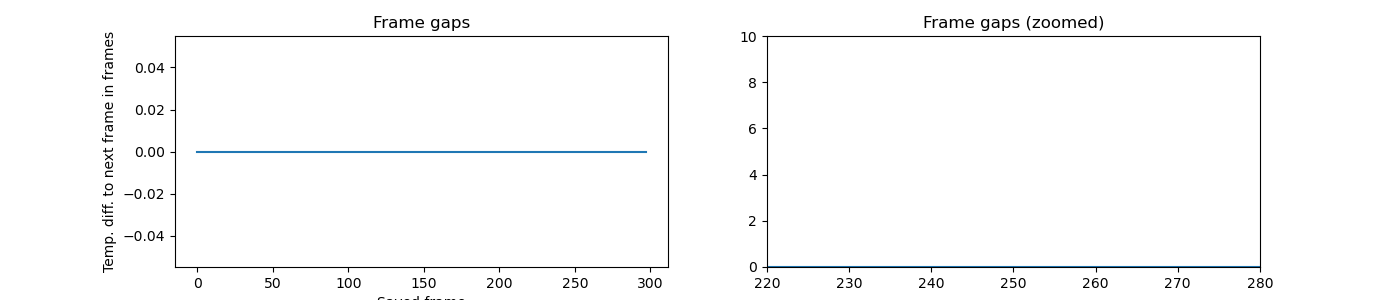

In [6]:
# Plot gaps between frames based on camera times
fig, axs = plt.subplots(1,2, figsize=(14,3))
for i_id, (ids, ts) in enumerate(zip(fr_idxs_all, timestamps_all)):
    print(f"==== Cam {i_id} ====")
    print("Maximum step in frame idx: ", np.max(np.diff(ids)))
    print("Maximum and minimum local fps: ", 1/np.min(np.diff(ts)), 1/np.max(np.diff(ts)))
    print(f"Number of frames with local fps < {int(0.75*framerate)}/s", np.sum(1/np.diff(ts) < 0.75*framerate))
    axs[0].plot(np.diff(ts)*framerate)
    axs[0].set_title("Frame gaps")
    axs[0].set_xlabel("Saved frame")
    axs[0].set_ylabel("Temp. diff. to next frame in frames")
    axs[1].plot(np.diff(ts)*framerate)
    axs[1].set_xlim((220,280))
    axs[1].set_ylim((0,10))
    axs[1].set_title("Frame gaps (zoomed)")
    axs[0].set_xlabel("Saved frame")

In [7]:
# Print first 10 saved frame idxs and cam times
for i_cam in range(len(files)):
    print("Cam ", i_cam)
    timestamps = []
    for i in range(10):
        md = readers[i_cam].get_meta_data(i)
        print(md)
        timestamps.append(md["timestamp"])
    timestamps = np.array(timestamps)
    print(np.diff(timestamps)/(1/framerate))

Cam  0
{'index': 66978814, 'timestamp': 1.9250017678539138e-289}
{'index': 7405682, 'timestamp': 1.8692263708832408e-306}
{'index': 7798899, 'timestamp': 1.4242075247841003e-306}
{'index': 7929974, 'timestamp': 2.0472377118523173e-306}
{'index': 7667820, 'timestamp': 2.670251601951416e-306}
{'index': 7929972, 'timestamp': 2.3142397843623156e-306}
{'index': 7536753, 'timestamp': 2.2252449786723653e-306}
{'index': 7405679, 'timestamp': 1.3796313524399387e-306}
{'index': 7929965, 'timestamp': 1.8692195803930926e-306}
{'index': 7471224, 'timestamp': 1.780226132759731e-306}
[-1.15500106e-287 -2.67011308e-305  3.73818112e-305  3.73808334e-305
 -2.13607091e-305 -5.33968834e-306 -5.07368176e-305  2.93752937e-305
 -5.33960686e-306]


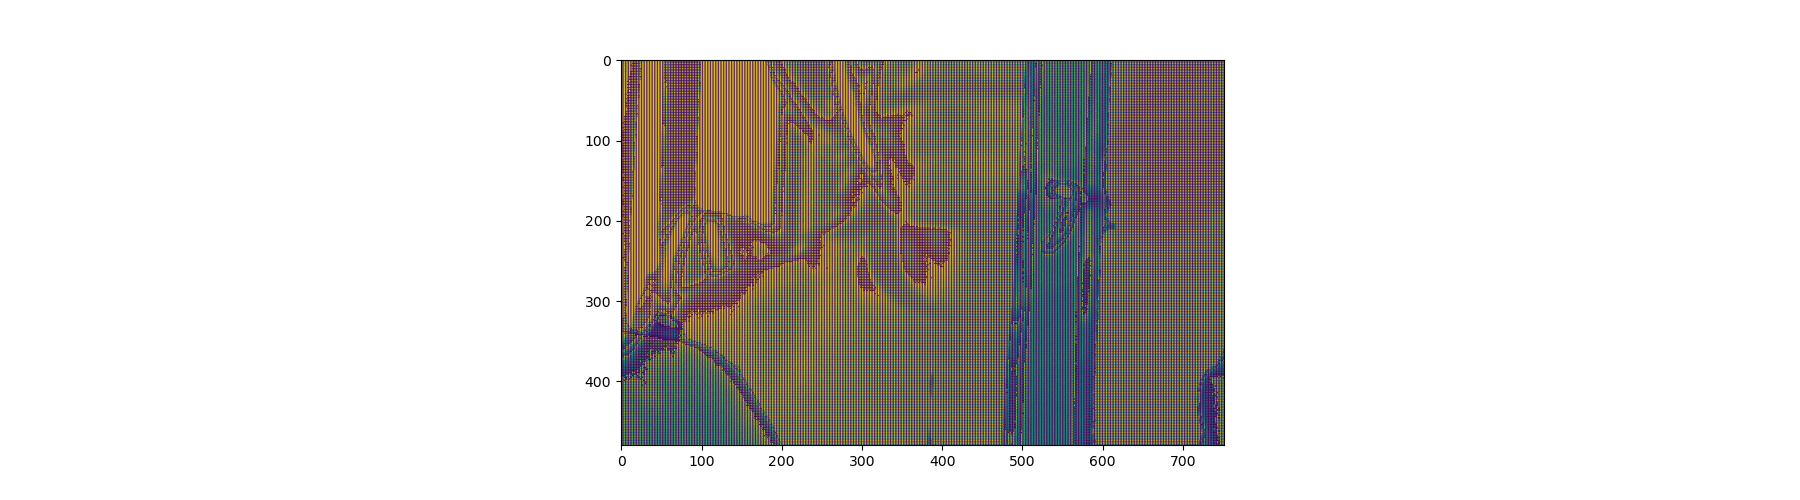

In [8]:
# Plot single frame from each cam
fig, axs = plt.subplots(1,len(files), figsize=(18,5), squeeze=False)
for ax,r in zip(axs[0],readers):
    ax.imshow(r.get_data(230))

In [9]:
# Print local frame rate
1/np.diff(timestamps)

array([-5.19480042e+288, -2.24709584e+306,  1.60505866e+306,
        1.60510065e+306, -2.80889552e+306, -1.12366109e+307,
       -1.18257319e+306,  2.04253277e+306, -1.12367823e+307])